
# 01. Exploratory Data Analysis (EDA)

## Cel notatnika

Celem tej analizy jest zbadanie zbioru danych  Default of Credit Card Clients.

Analiza będzie skupiona na:
- Zrozumieniu struktury zbioru oraz jego zawartości,
- Sprawdzenie zależności między zmiennymi a finalną predykcją
- Sprawdzenie jakości danych,
- Poszukanie wzoru który może być kluczowy do przewidywania

Efekty tej części pracy będą wsparciem do późniejszego preprocessingu danych, zbudowania modelu oraz kalibracji prawdopodobieństw.

## Zbiór

Source: UCI Machine Learning Repository – Default of Credit Card Clients

Analiza korzysta z zbioru utworzonego i wyeksportowanego w notatniku:`00_pozyskanie_danych.ipynb`.


In [4]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (p for p in [current_path, *current_path.parents]
    if (p/"src").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder src not found.")

#Add project root to Python import paths
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))

print("Project catalog:", PROJECT_ROOT)

from src import data_loader as dl

CONFIG_PATH = PROJECT_ROOT / "config.yaml"
config = dl.load_config(CONFIG_PATH)

PROCESSED_DATA_PATH = dl.get_data_path(config, PROJECT_ROOT, "processed_dir")

print("Project root:", PROJECT_ROOT)
print("Processed data path:", PROCESSED_DATA_PATH)
print("Libraries imported successfully.")


Project catalog: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration
Project root: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration
Processed data path: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration\data\processed
Libraries imported successfully.


In [7]:
DATA_FILE = PROCESSED_DATA_PATH / "credit_default_data.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Data file {DATA_FILE} not found. Please run the data processing script first.")

credits_df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Dataset shape:", credits_df.shape)

display(credits_df.head())
credits_df.info()

Dataset loaded successfully.
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [18]:
TARGET_COLUMN = credits_df.columns[-1]  

target_counts = credits_df[TARGET_COLUMN].value_counts().sort_index()
target_percentages = credits_df[TARGET_COLUMN].value_counts(normalize=True) * 100

target_distribution_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_distribution_df)

,Count,Percentage
default payment next month,,
0,23364,77.88
1,6636,22.12


C:\Users\justy\AppData\Local\Temp\ipykernel_13072\1731514815.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=credits_df, x=TARGET_COLUMN, palette="Set2")


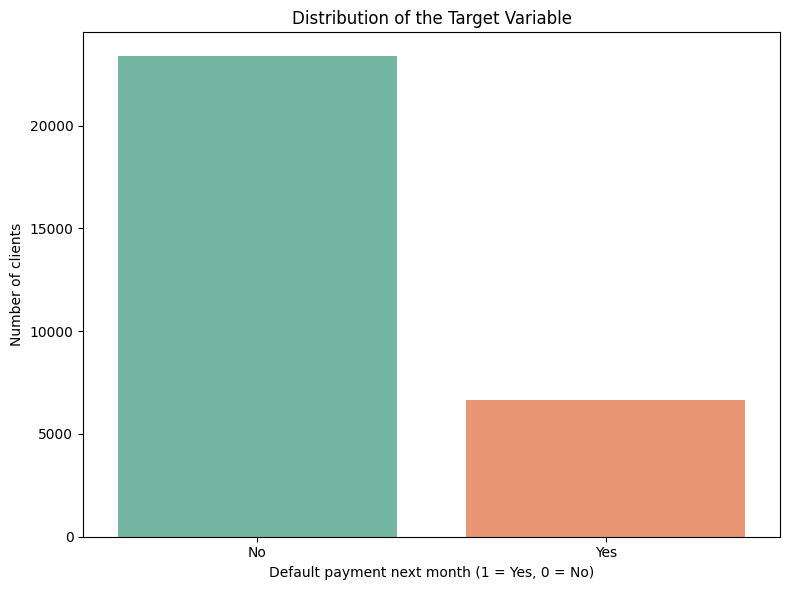

In [20]:
plt.figure(figsize=(8, 6))
sns.countplot(data=credits_df, x=TARGET_COLUMN, palette="Set2")

plt.title(f"Distribution of the Target Variable")
plt.xlabel("Default payment next month (1 = Yes, 0 = No)") #1 opózniona
plt.ylabel("Number of clients")
plt.xticks(ticks=[0, 1], labels=["No", "Yes"])
plt.tight_layout()
plt.show()


### 1. Dystrybucja zmiennej prognozowej

Balans zmiennej celowej:
- klasa 0 (terminowa płatność): 23 364 obserwacje (78%)
- klasa 1 (opóźnienie w płatności): 6 636 obserwacji (22%)

Klasa większościowa liczy w przybliżeniu 3,5 raza więcej obserwacji niż klasa mniejszościowa. 
Ta nierównowaga klas oznacza, że sama dokładność (accuracy) może być myląca przy ocenie modeli klasyfikacyjnych. Dalsza ewaluacja modelu powinna uwzględniać metryki biorące pod uwagę klasę mniejszościową, takie jak czułość (recall), precyzja (precision), miara F1 (F1-score) oraz ROC-AUC. 
Na tym etapie nie zastosowano żadnych technik ponownego próbkowania (resampling).
